# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [15]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import nltk

nltk.download('gutenberg')
nltk.download('punkt')  # Requerido para la tokenización de oraciones

[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\andyj\AppData\Roaming\nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\andyj\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\andyj\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [17]:
from nltk.corpus import gutenberg

# Lista con los 18 identificadores de archivo
file_ids = gutenberg.fileids()
print("Archivos disponibles (18):")
for f in file_ids:
    print(f"- {f}")


Archivos disponibles (18):
- austen-emma.txt
- austen-persuasion.txt
- austen-sense.txt
- bible-kjv.txt
- blake-poems.txt
- bryant-stories.txt
- burgess-busterbrown.txt
- carroll-alice.txt
- chesterton-ball.txt
- chesterton-brown.txt
- chesterton-thursday.txt
- edgeworth-parents.txt
- melville-moby_dick.txt
- milton-paradise.txt
- shakespeare-caesar.txt
- shakespeare-hamlet.txt
- shakespeare-macbeth.txt
- whitman-leaves.txt


In [18]:
import time
import re
import numpy as np
import pandas as pd
import nltk
from nltk.corpus import gutenberg

# 1. Cargar textos originales e identificar documentos y sus tamaños
file_ids = gutenberg.fileids()
print(f"Número total de documentos: {len(file_ids)}\n")

print(f"{'ID Documento':<30} | {'Caracteres':<12} | {'Palabras (raw)':<15}")
print("-" * 65)
for fid in file_ids:
    raw_len = len(gutenberg.raw(fid))
    words_len = len(gutenberg.words(fid))
    print(f"{fid:<30} | {raw_len:<12,} | {words_len:<15,}")

# Configuration de preprocesamiento consistente:
# - Conversión a minúsculas
# - Eliminación de puntuación y caracteres especiales (solo se conservan caracteres alfanuméricos)
def preprocess_text(text):
    text_lower = text.lower()
    # Extraer únicamente tokens alfanuméricos
    tokens = re.findall(r'\b\w+\b', text_lower)
    return tokens

# Procesar y almacenar los documentos en memoria para los experimentos
corpus_preprocessed = {
    fid: preprocess_text(gutenberg.raw(fid)) 
    for fid in file_ids
}

print("\nConfiguración de preprocesamiento completada.")

Número total de documentos: 18

ID Documento                   | Caracteres   | Palabras (raw) 
-----------------------------------------------------------------
austen-emma.txt                | 887,071      | 192,427        
austen-persuasion.txt          | 466,292      | 98,171         
austen-sense.txt               | 673,022      | 141,576        
bible-kjv.txt                  | 4,332,554    | 1,010,654      
blake-poems.txt                | 38,153       | 8,354          
bryant-stories.txt             | 249,439      | 55,563         
burgess-busterbrown.txt        | 84,663       | 18,963         
carroll-alice.txt              | 144,395      | 34,110         
chesterton-ball.txt            | 457,450      | 96,996         
chesterton-brown.txt           | 406,629      | 86,063         
chesterton-thursday.txt        | 320,525      | 69,213         
edgeworth-parents.txt          | 935,158      | 210,663        
melville-moby_dick.txt         | 1,242,990    | 260,819        
milton

**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [19]:
def sequential_search(term, corpus):
    """
    Realiza una búsqueda secuencial de un término en la colección de documentos.
    Utiliza obligatoriamente dos lazos 'for' anidados.
    """
    matching_docs = []
    term_normalized = term.lower()
    
    # Lazos for anidados obligatorios:
    # 1. Primer lazo: recorre los documentos
    for doc_id, tokens in corpus.items():
        # 2. Segundo lazo: recorre los tokens del documento
        for token in tokens:
            if token == term_normalized:
                matching_docs.append(doc_id)
                break  # Se encontró el término en el documento, se pasa al siguiente
                
    return matching_docs

# Pruebas con términos con distintas frecuencias
frequent_term = "the"
infrequent_term = "whale"
nonexistent_term = "xyzunexistentterm"

print(f"Resultados para '{frequent_term}': {len(sequential_search(frequent_term, corpus_preprocessed))} docs")
print(f"Resultados para '{infrequent_term}': {sequential_search(infrequent_term, corpus_preprocessed)}")
print(f"Resultados para '{nonexistent_term}': {sequential_search(nonexistent_term, corpus_preprocessed)}")

Resultados para 'the': 18 docs
Resultados para 'whale': ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
Resultados para 'xyzunexistentterm': []


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [20]:
def measure_time_ns(search_fn, term, corpus, num_runs=30):
    """
    Mide el tiempo promedio de ejecución de 30 corridas usando time.perf_counter_ns().
    Retorna el tiempo medio en milisegundos (ms).
    """
    times = []
    for _ in range(num_runs):
        start_time = time.perf_counter_ns()
        _ = search_fn(term, corpus)
        end_time = time.perf_counter_ns()
        times.append(end_time - start_time)
    
    # Calcular media en nanosegundos y convertir a milisegundos (1 ms = 1,000,000 ns)
    mean_ms = (sum(times) / num_runs) / 1e6
    return mean_ms

terms_to_test = [frequent_term, infrequent_term, nonexistent_term]

print(f"{'Término':<20} | {'Tiempo Medio (ms)':<20}")
print("-" * 45)
for term in terms_to_test:
    t_ms = measure_time_ns(sequential_search, term, corpus_preprocessed, num_runs=30)
    print(f"{term:<20} | {t_ms:<20.4f}")

Término              | Tiempo Medio (ms)   
---------------------------------------------
the                  | 0.0053              
whale                | 25.1641             
xyzunexistentterm    | 37.7343             


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [21]:
class InvertedIndex:
    def __init__(self, corpus):
        self.index = {}
        self.doc_ids = sorted(list(corpus.keys()))
        self.build_index(corpus)
        
    def build_index(self, corpus):
        for doc_id, tokens in corpus.items():
            for token in tokens:
                if token not in self.index:
                    self.index[token] = set()
                self.index[token].add(doc_id)
        
        # Convertir conjuntos a listas ordenadas (Posting lists)
        for token in self.index:
            self.index[token] = sorted(list(self.index[token]))
            
    def get_postings(self, term):
        return self.index.get(term.lower(), [])
    
    def get_df(self, term):
        """Calcula la frecuencia documental (Document Frequency)."""
        return len(self.get_postings(term))
    
    # Consultas de un término
    def query_single(self, term):
        return self.get_postings(term)
    
    # Operaciones booleanas
    def query_and(self, term1, term2):
        p1 = set(self.get_postings(term1))
        p2 = set(self.get_postings(term2))
        return sorted(list(p1.intersection(p2)))
    
    def query_or(self, term1, term2):
        p1 = set(self.get_postings(term1))
        p2 = set(self.get_postings(term2))
        return sorted(list(p1.union(p2)))
    
    def query_not(self, term):
        p = set(self.get_postings(term))
        all_docs = set(self.doc_ids)
        return sorted(list(all_docs.difference(p)))

# Construir el índice
inverted_index = InvertedIndex(corpus_preprocessed)

# Inspección de Posting lists y DF
print(f"DF de 'whale': {inverted_index.get_df('whale')}")
print(f"Postings de 'whale': {inverted_index.get_postings('whale')}\n")

# Consultas booleanas de prueba
print("AND ('whale' AND 'sea'):", inverted_index.query_and('whale', 'sea'))
print("OR ('whale' OR 'monster'):", inverted_index.query_or('whale', 'monster'))
print("NOT ('the'):", len(inverted_index.query_not('the')), "documentos")

DF de 'whale': 6
Postings de 'whale': ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']

AND ('whale' AND 'sea'): ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
OR ('whale' OR 'monster'): ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
NOT ('the'): 0 documentos


**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [22]:
def measure_index_time_ns(index_fn, *args, num_runs=30):
    times = []
    for _ in range(num_runs):
        start = time.perf_counter_ns()
        _ = index_fn(*args)
        end = time.perf_counter_ns()
        times.append(end - start)
    return (sum(times) / num_runs) / 1e6

test_queries = ["the", "whale", "gutenberg", "xyzunexistentterm"]

results = []

for term in test_queries:
    # 1. Recuperar resultados
    seq_docs = sorted(sequential_search(term, corpus_preprocessed))
    idx_docs = inverted_index.query_single(term)
    
    # 2. Comprobar igualdad exacta de resultados
    are_equal = (seq_docs == idx_docs)
    
    # 3. Medir tiempos promedio
    t_seq = measure_time_ns(sequential_search, term, corpus_preprocessed, num_runs=30)
    t_idx = measure_index_time_ns(inverted_index.query_single, term, num_runs=30)
    
    results.append({
        "Término": term,
        "Iguales": are_equal,
        "Tiempo Secuencial (ms)": round(t_seq, 4),
        "Tiempo Índice (ms)": round(t_idx, 6),
        "Aceleración (Speedup)": f"{round(t_seq / t_idx, 2)}x" if t_idx > 0 else "N/A"
    })

# Representación tabulada
df_comparison = pd.DataFrame(results)
print(df_comparison.to_string(index=False))

          Término  Iguales  Tiempo Secuencial (ms)  Tiempo Índice (ms) Aceleración (Speedup)
              the     True                  0.0047            0.000270                17.33x
            whale     True                 24.2074            0.000557              43486.4x
        gutenberg     True                 38.4489            0.000677             56821.01x
xyzunexistentterm     True                 37.5750            0.000543             69156.45x


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [23]:
import tarfile
import re
from pathlib import Path

# Ubicación del archivo tar
tar_path = Path("gutenberg_large/txt-files.tar")
if not tar_path.exists():
    tar_path = Path("txt-files.tar")

valid_files = []
book_ids = set()

print("Escaneando el archivo tar para filtrar documentos válidos...")
with tarfile.open(tar_path, "r") as tar:
    for member in tar:
        # Filtrar solo archivos .txt
        if member.isfile() and member.name.endswith(".txt"):
            # Evitar versiones duplicadas del mismo libro (ej. -0.txt, -8.txt)
            match = re.search(r'pg(\d+)', member.name)
            if match:
                book_id = match.group(1)
                if book_id not in book_ids:
                    book_ids.add(book_id)
                    valid_files.append(member.name)

print(f"Cantidad total de documentos válidos identificados: {len(valid_files)}")

Escaneando el archivo tar para filtrar documentos válidos...
Cantidad total de documentos válidos identificados: 78145


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [24]:
import time

def load_and_preprocess_from_tar(tar_path, valid_member_names, max_docs):
    """
    Lee los documentos directamente desde el archivo .tar en memoria
    y aplica la misma configuración de preprocesamiento de la Parte A.
    """
    subset_corpus = {}
    target_members = set(valid_member_names[:max_docs])
    
    with tarfile.open(tar_path, "r") as tar:
        for member in tar:
            if member.name in target_members:
                f = tar.extractfile(member)
                if f is not None:
                    # Leer y decodificar el contenido ignorando errores de caracteres
                    raw_text = f.read().decode('utf-8', errors='ignore')
                    # Preprocesar con la misma regla de la Parte A
                    subset_corpus[member.name] = preprocess_text(raw_text)
                if len(subset_corpus) >= max_docs:
                    break
                    
    return subset_corpus

# 1. Definir subconjunto de prueba (por ejemplo, 100 documentos)
subset_size = 100
print(f"Cargando y tokenizando {subset_size} documentos directamente desde el .tar...")

large_corpus = load_and_preprocess_from_tar(tar_path, valid_files, max_docs=subset_size)

# Calcular el número total de tokens procesados
total_tokens = sum(len(tokens) for tokens in large_corpus.values())
print(f"Subconjunto cargado: {len(large_corpus)} documentos ({total_tokens:,} tokens en total).\n")

# 2. Ejecutar Búsqueda Secuencial
target_term = "gutenberg"
t_seq_large = measure_time_ns(sequential_search, target_term, large_corpus, num_runs=30)
res_seq = sorted(sequential_search(target_term, large_corpus))

# 3. Construir Índice Invertido
large_index = InvertedIndex(large_corpus)
t_idx_large = measure_index_time_ns(large_index.query_single, target_term, num_runs=30)
res_idx = large_index.query_single(target_term)

# 4. Comprobar la igualdad de resultados y comparar tiempos
are_identical = (res_seq == res_idx)

print("--- Comparación de Rendimiento (Corpus Grande - Subconjunto) ---")
print(f"¿Los resultados son idénticos?: {are_identical}")
print(f"Documentos que contienen '{target_term}': {len(res_seq)}")
print(f"Tiempo Medio Búsqueda Secuencial: {t_seq_large:.4f} ms")
print(f"Tiempo Medio Índice Invertido:    {t_idx_large:.6f} ms")
print(f"Aceleración (Speedup):           {t_seq_large / t_idx_large:.2f}x")

Cargando y tokenizando 100 documentos directamente desde el .tar...
Subconjunto cargado: 100 documentos (5,787,336 tokens en total).

--- Comparación de Rendimiento (Corpus Grande - Subconjunto) ---
¿Los resultados son idénticos?: True
Documentos que contienen 'gutenberg': 100
Tiempo Medio Búsqueda Secuencial: 0.0129 ms
Tiempo Medio Índice Invertido:    0.000403 ms
Aceleración (Speedup):           31.99x


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

Iniciando experimentos de escalabilidad...

Procesando subconjunto de n = 50 documentos...
Procesando subconjunto de n = 100 documentos...
Procesando subconjunto de n = 250 documentos...
Procesando subconjunto de n = 500 documentos...
Procesando subconjunto de n = 1000 documentos...

Resultados experimentales recopilados:
 n_docs  total_tokens  t_seq_ms  t_idx_ms
     50       2416148  0.007080  0.000577
    100       5787336  0.013433  0.000590
    250      18794756  0.036957  0.000507
    500      35944391  0.070093  0.000520
   1000      73325886  0.214780  0.000703


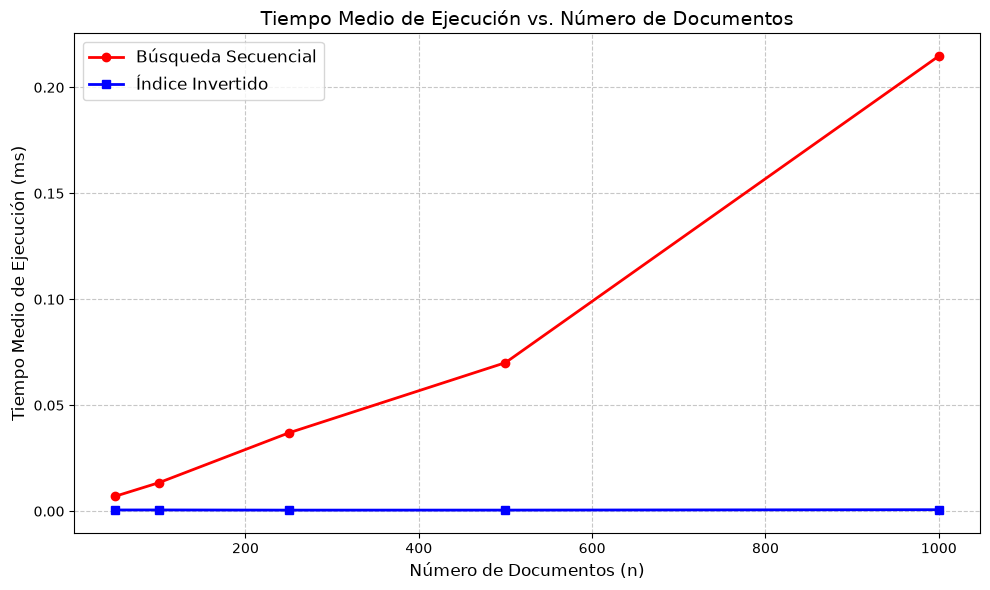

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Definir tamaños crecientes del corpus
corpus_sizes = [50, 100, 250, 500, 1000]
target_term = "gutenberg"

results_c = []

print("Iniciando experimentos de escalabilidad...\n")

for n in corpus_sizes:
    if len(valid_files) < n:
        print(f"El corpus solo cuenta con {len(valid_files)} documentos válidos. Deteniendo en n={n}.")
        break
        
    print(f"Procesando subconjunto de n = {n} documentos...")
    
    # Cargar subconjunto de n documentos
    corpus_subset = load_and_preprocess_from_tar(tar_path, valid_files, max_docs=n)
    num_tokens = sum(len(tokens) for tokens in corpus_subset.values())
    
    # Medir tiempo medio de Búsqueda Secuencial (30 corridas)
    t_seq_ms = measure_time_ns(sequential_search, target_term, corpus_subset, num_runs=30)
    
    # Construir índice e medir tiempo medio con Índice Invertido (30 corridas)
    idx_subset = InvertedIndex(corpus_subset)
    t_idx_ms = measure_index_time_ns(idx_subset.query_single, target_term, num_runs=30)
    
    results_c.append({
        'n_docs': len(corpus_subset),
        'total_tokens': num_tokens,
        't_seq_ms': t_seq_ms,
        't_idx_ms': t_idx_ms
    })

df_results_c = pd.DataFrame(results_c)
print("\nResultados experimentales recopilados:")
print(df_results_c.to_string(index=False))

# 2. Generar gráfica de tiempo medio en función del número de documentos
plt.figure(figsize=(10, 6))
plt.plot(df_results_c['n_docs'], df_results_c['t_seq_ms'], marker='o', color='red', linewidth=2, label='Búsqueda Secuencial')
plt.plot(df_results_c['n_docs'], df_results_c['t_idx_ms'], marker='s', color='blue', linewidth=2, label='Índice Invertido')

plt.title('Tiempo Medio de Ejecución vs. Número de Documentos', fontsize=14)
plt.xlabel('Número de Documentos (n)', fontsize=12)
plt.ylabel('Tiempo Medio de Ejecución (ms)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

=== FUNCIONES DE TIEMPO ESTIMADAS t = f(n) ===
1. Búsqueda Secuencial:
   t(n) = 0.000217 * n + -0.013879 (ms)
   R^2  = 0.9698

2. Índice Invertido:
   t(n) = 0.00000013 * n + 0.000531 (ms)
   R^2  = 0.4057



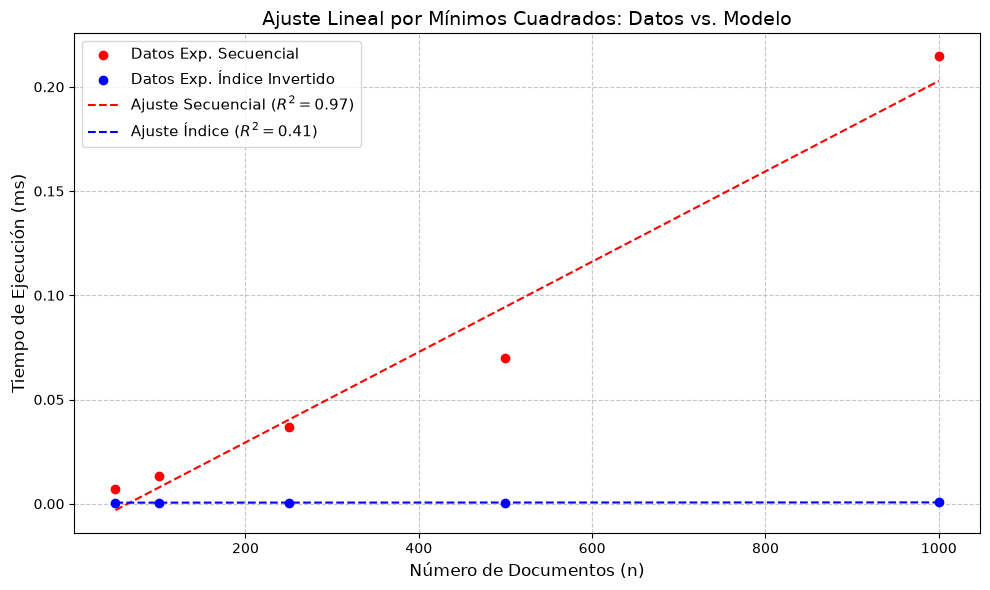

In [26]:
from scipy.stats import linregress

n_values = df_results_c['n_docs'].values
t_seq_values = df_results_c['t_seq_ms'].values
t_idx_values = df_results_c['t_idx_ms'].values

# Regresión lineal para Búsqueda Secuencial
slope_seq, intercept_seq, r_val_seq, p_val_seq, std_err_seq = linregress(n_values, t_seq_values)
r2_seq = r_val_seq ** 2

# Regresión lineal para Índice Invertido
slope_idx, intercept_idx, r_val_idx, p_val_idx, std_err_idx = linregress(n_values, t_idx_values)
r2_idx = r_val_idx ** 2

print("=== FUNCIONES DE TIEMPO ESTIMADAS t = f(n) ===")
print(f"1. Búsqueda Secuencial:")
print(f"   t(n) = {slope_seq:.6f} * n + {intercept_seq:.6f} (ms)")
print(f"   R^2  = {r2_seq:.4f}\n")

print(f"2. Índice Invertido:")
print(f"   t(n) = {slope_idx:.8f} * n + {intercept_idx:.6f} (ms)")
print(f"   R^2  = {r2_idx:.4f}\n")

# Gráfica de Datos Experimentales vs. Funciones Ajustadas
plt.figure(figsize=(10, 6))

# Puntos experimentales
plt.scatter(n_values, t_seq_values, color='red', label='Datos Exp. Secuencial', zorder=3)
plt.scatter(n_values, t_idx_values, color='blue', label='Datos Exp. Índice Invertido', zorder=3)

# Líneas ajustadas
n_smooth = np.linspace(min(n_values), max(n_values), 100)
plt.plot(n_smooth, slope_seq * n_smooth + intercept_seq, 'r--', label=f'Ajuste Secuencial ($R^2={r2_seq:.2f}$)')
plt.plot(n_smooth, slope_idx * n_smooth + intercept_idx, 'b--', label=f'Ajuste Índice ($R^2={r2_idx:.2f}$)')

plt.title('Ajuste Lineal por Mínimos Cuadrados: Datos vs. Modelo', fontsize=14)
plt.xlabel('Número de Documentos (n)', fontsize=12)
plt.ylabel('Tiempo de Ejecución (ms)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()